# ST2195 Programming Coursework Part 1

Name: Darren Alexander



Acceptance Rate: 0.6995
Sample Mean:     0.0391
Sample Std Dev:  1.3763


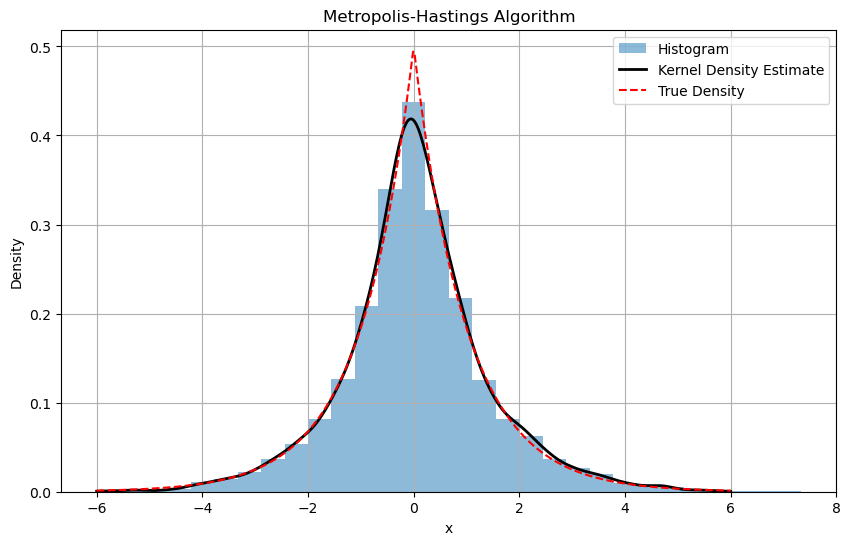

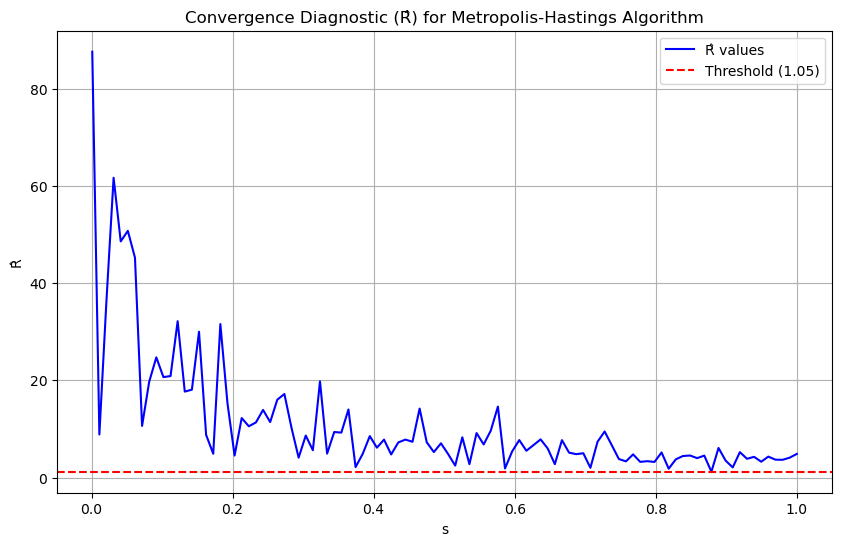

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import laplace
from scipy.stats import gaussian_kde

# ----------------------------
# Metropolis-Hastings algorithm
# ----------------------------
def metropolis_hastings(N, s):
    x = np.zeros(N)
    accept = 0
    for i in range(1, N):
        x_star = np.random.normal(x[i - 1], s)
        ratio = np.exp(-abs(x_star)) / np.exp(-abs(x[i - 1]))
        u = np.random.uniform(0, 1)
        if np.log(u) < np.log(ratio):
            x[i] = x_star
            accept += 1
        else:
            x[i] = x[i - 1]
    acceptance_rate = accept / (N - 1)
    return x, acceptance_rate

# ----------------------------
# Gelman-Rubin R̂ Diagnostic
# ----------------------------
def calculate_Rb(chains):
    J = len(chains)
    N = len(chains[0])

    Mj = np.mean(chains, axis=1)
    Vj = np.var(chains, axis=1, ddof=1)

    W = np.mean(Vj)
    M = np.mean(Mj)
    B = N / (J - 1) * np.sum((Mj - M) ** 2)

    Rb = np.sqrt((B + W) / W)
    return Rb

#-----------------------------
# Part 1(a) Sampling and Plotting
#-----------------------------
N = 10000
s = 1
samples, acceptance_rate = metropolis_hastings(N, s)

# Monte Carlo Estimates
sample_mean = np.mean(samples)
sample_std = np.std(samples)

print(f"Acceptance Rate: {acceptance_rate:.4f}")
print(f"Sample Mean:     {sample_mean:.4f}")
print(f"Sample Std Dev:  {sample_std:.4f}")

# Plot Histogram, Kernel Density Plot, and True Density
kde = gaussian_kde(samples)
x_vals = np.linspace(-6, 6, 500)
kde_vals = kde(x_vals)
plt.figure(figsize=(10, 6))
plt.hist(samples, bins=30, density=True, alpha=0.5, label='Histogram')
plt.plot(x_vals, kde_vals, color='black', linewidth=2, label='Kernel Density Estimate')
plt.plot(x_vals, laplace.pdf(x_vals, loc=0, scale=1), 'r--', label='True Density')
plt.title('Metropolis-Hastings Algorithm')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.grid(True)
plt.show()

#-----------------------------
# Part 1(b): R̂ Diagnostic
#-----------------------------
J = 4
N_short = 2000
s_values = np.linspace(0.001, 1, 100)
Rb_values = []

for s in s_values:
    chains = np.array([metropolis_hastings(N_short, s)[0] for _ in range(J)])
    Rb = calculate_Rb(chains)
    Rb_values.append(Rb)

# Plot R̂ values
plt.figure(figsize=(10, 6))
plt.plot(s_values, Rb_values, color='blue', label='R̂ values')
plt.axhline(y=1.05, color='red', linestyle='--', label='Threshold (1.05)')
plt.title('Convergence Diagnostic (R̂) for Metropolis-Hastings Algorithm')
plt.xlabel('s')
plt.ylabel('R̂')
plt.legend()
plt.grid(True)
plt.show()